# Análise quantitativa de retorno, risco e exposição ao mercado de ativos brasileiros

## Objetivo

Este projeto analisa o comportamento histórico dos ativos PETR4, VALE3,
ITUB4 e BOVA11 em termos de retorno, risco e exposição ao mercado.

O BOVA11 será utilizado como uma aproximação do mercado acionário brasileiro.

## Metodologia inicial

Serão utilizados dados diários ajustados dos últimos cinco anos.

As principais métricas analisadas serão:

- retorno acumulado;
- retorno anualizado;
- volatilidade;
- drawdown;
- correlação com o BOVA11;
- beta em relação ao mercado;
- Sharpe Ratio.

In [4]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", None)

# Caminhos do projeto (funciona rodando de dentro da pasta notebooks/ ou da raiz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)


def salvar_figura(nome):
    """Salva o gráfico atual em figures/ com boa resolução."""
    plt.savefig(FIG_DIR / nome, dpi=150, bbox_inches="tight")


print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


## 1. Coleta dos dados

Nesta etapa, serão coletados dados diários dos ativos PETR4, VALE3,
ITUB4 e BOVA11, negociados na B3.

O período escolhido será de aproximadamente cinco anos.

In [5]:
tickers = [
    "PETR4.SA",
    "VALE3.SA",
    "ITUB4.SA",
    "BOVA11.SA"
]

PERIODO = "5y"
CSV_PRECOS = DATA_DIR / "precos_ajustados.csv"

print("Ativos:", tickers)
print("Período:", PERIODO)

Ativos: ['PETR4.SA', 'VALE3.SA', 'ITUB4.SA', 'BOVA11.SA']
Período: 5y


In [6]:
import time


def carregar_csv(caminho):
    """Lê o CSV salvo. Retorna None se não existir ou se estiver vazio/inválido."""
    if not caminho.exists() or caminho.stat().st_size == 0:
        return None
    try:
        df = pd.read_csv(caminho, index_col="Date", parse_dates=True)
    except ValueError:
        return None
    if df.empty or not set(tickers).issubset(df.columns):
        return None
    df.columns.name = "Ticker"
    return df


def baixar_ativo(ticker, tentativas=3, espera=10):
    """Baixa um ativo do Yahoo Finance, tentando de novo se vier vazio."""
    for n in range(1, tentativas + 1):
        df = yf.download(
            ticker,
            period=PERIODO,
            auto_adjust=True,
            progress=False,
            threads=False
        )
        if not df.empty:
            close = df["Close"]
            if isinstance(close, pd.DataFrame):  # versões novas do yfinance
                close = close.iloc[:, 0]
            print(f"{ticker}: {len(close)} linhas baixadas.")
            return close.rename(ticker)
        print(f"{ticker}: tentativa {n}/{tentativas} sem dados.")
        if n < tentativas:
            time.sleep(espera)
    raise RuntimeError(
        f"Não foi possível baixar {ticker} do Yahoo Finance. "
        "Verifique a internet (desligue VPN/proxy), aguarde alguns minutos "
        "e rode esta célula de novo."
    )


# Se o CSV já existe e é válido, usa os dados salvos (resultados reproduzíveis).
# Caso contrário, baixa cada ativo do Yahoo Finance e salva em data/.
prices = carregar_csv(CSV_PRECOS)

if prices is not None:
    print("Dados carregados de:", CSV_PRECOS.name)
else:
    prices = pd.concat([baixar_ativo(t) for t in sorted(tickers)], axis=1)
    prices.columns.name = "Ticker"

    print("Valores ausentes antes da limpeza:")
    print(prices.isna().sum())

    prices = prices.dropna()
    if prices.empty:
        raise RuntimeError(
            "Os ativos baixados não têm datas em comum. Rode a célula novamente."
        )

    prices.index.name = "Date"
    prices.to_csv(CSV_PRECOS)  # só salva se houver dados válidos
    print("Dados baixados e salvos em:", CSV_PRECOS.name)

c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

BOVA11.SA: 1247 linhas baixadas.


c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See 

ITUB4.SA: 1248 linhas baixadas.


c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See 

PETR4.SA: 1248 linhas baixadas.
VALE3.SA: 1248 linhas baixadas.
Valores ausentes antes da limpeza:
Ticker
BOVA11.SA    1
ITUB4.SA     0
PETR4.SA     0
VALE3.SA     0
dtype: int64
Dados baixados e salvos em: precos_ajustados.csv


c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\fmodolo001\Downloads\analise-quantitativa-ativos-brasileiros\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See 

In [7]:
print("Formato dos dados:", prices.shape)
print("Primeira data:", prices.index.min().date())
print("Última data:", prices.index.max().date())
print("Valores ausentes:", int(prices.isna().sum().sum()))

prices.head()

Formato dos dados: (1247, 4)
Primeira data: 2021-10-22
Última data: 2026-10-22
Valores ausentes: 0


Ticker,BOVA11.SA,ITUB4.SA,PETR4.SA,VALE3.SA
Date,,,,
2021-10-22,102.330002,15.110293,8.037954,50.314560
2021-10-25,104.550003,15.405560,8.588016,50.923000
2021-10-26,102.250000,15.238672,8.505210,50.380703
2021-10-27,102.400002,15.354215,8.484508,49.236584
2021-10-28,100.610001,15.322120,8.564355,48.740570


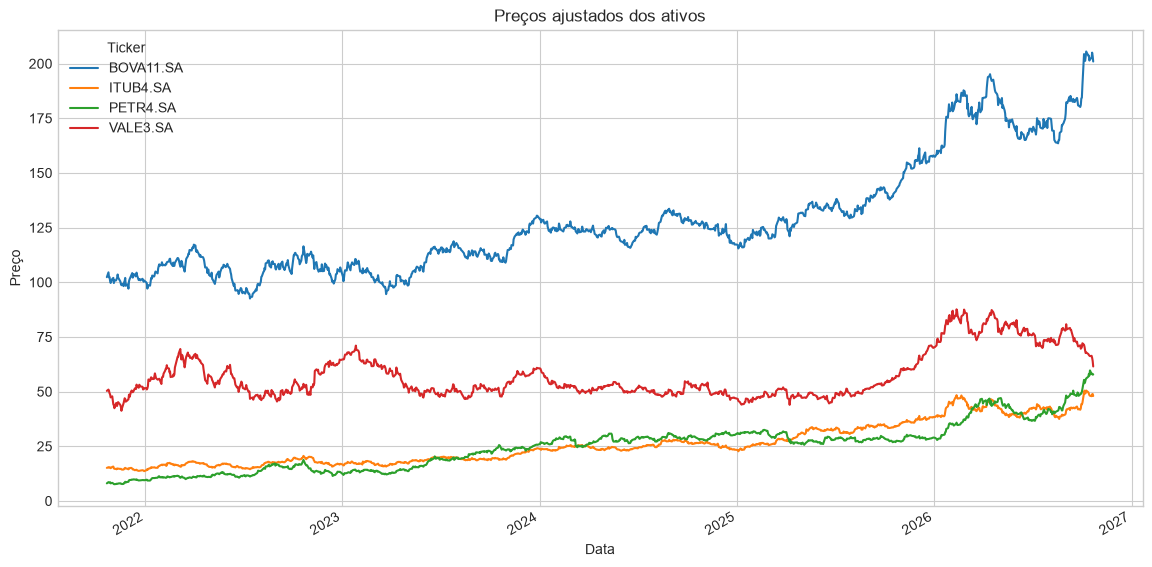

In [8]:
prices.plot(
    figsize=(14, 7),
    title="Preços ajustados dos ativos"
)

plt.xlabel("Data")
plt.ylabel("Preço")
salvar_figura("precos_ajustados.png")
plt.show()

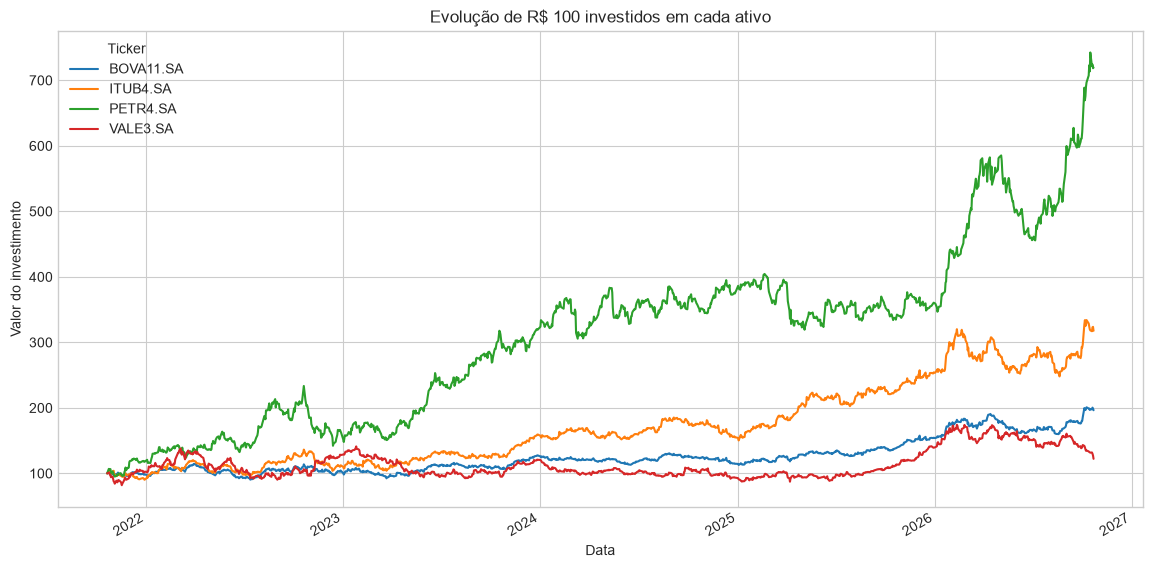

In [9]:
normalized_prices = prices / prices.iloc[0] * 100

normalized_prices.plot(
    figsize=(14, 7),
    title="Evolução de R$ 100 investidos em cada ativo"
)

plt.xlabel("Data")
plt.ylabel("Valor do investimento")
salvar_figura("precos_normalizados.png")
plt.show()

## 2. Retorno acumulado

O retorno acumulado mede a variação total de um investimento durante
todo o período analisado.

In [10]:
cumulative_return = prices.iloc[-1] / prices.iloc[0] - 1

print("Retorno acumulado:")
print((cumulative_return * 100).round(2))

Retorno acumulado:
Ticker
BOVA11.SA     96.38
ITUB4.SA     217.66
PETR4.SA     619.46
VALE3.SA      22.21
dtype: float64


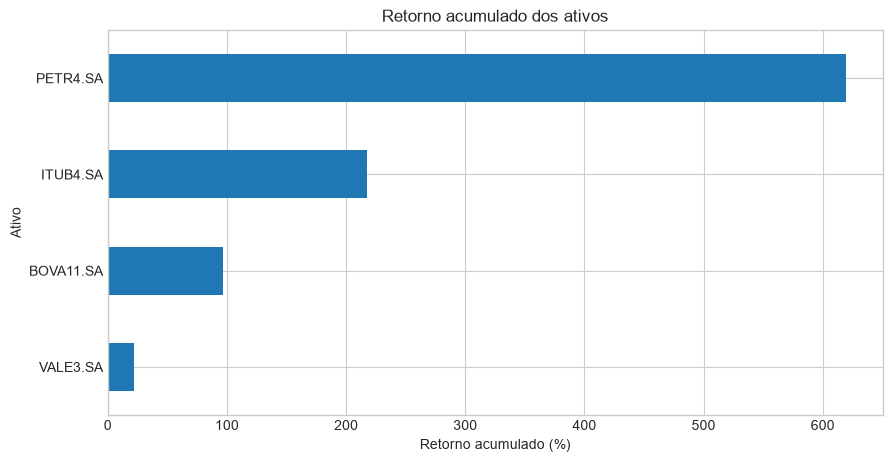

In [11]:
ax = (cumulative_return.sort_values() * 100).plot(
    kind="barh",
    figsize=(10, 5),
    title="Retorno acumulado dos ativos"
)

ax.set_xlabel("Retorno acumulado (%)")
ax.set_ylabel("Ativo")
salvar_figura("retorno_acumulado.png")
plt.show()

### Interpretação do retorno acumulado

No período analisado, PETR4 apresentou o maior retorno acumulado,
com valorização de 619,46%. VALE3 apresentou o menor desempenho,
com retorno acumulado de 22,21%.

Entretanto, essa comparação considera apenas o retorno total e não
leva em conta o risco assumido por cada ativo. Portanto, não é possível
concluir que PETR4 foi o melhor investimento sem analisar também sua
volatilidade, seus drawdowns e seu retorno ajustado ao risco.

## 3. Retornos diários

O retorno simples diário é calculado pela fórmula:

\[
R_t = \frac{P_t}{P_{t-1}} - 1
\]

em que \(P_t\) é o preço atual e \(P_{t-1}\) é o preço do dia anterior.

In [12]:
returns = prices.pct_change().dropna()

returns.head()

Ticker,BOVA11.SA,ITUB4.SA,PETR4.SA,VALE3.SA
Date,,,,
2021-10-25,0.021695,0.019541,0.068433,0.012093
2021-10-26,-0.021999,-0.010833,-0.009642,-0.010649
2021-10-27,0.001467,0.007582,-0.002434,-0.022709
2021-10-28,-0.017480,-0.002090,0.009411,-0.010074
2021-10-29,-0.009244,-0.023461,-0.062500,-0.028358


In [13]:
daily_volatility = returns.std()

print("Volatilidade diária:")
print((daily_volatility * 100).round(2))

Volatilidade diária:
Ticker
BOVA11.SA    1.15
ITUB4.SA     1.49
PETR4.SA     1.98
VALE3.SA     1.83
dtype: float64


In [14]:
annualized_volatility = returns.std() * np.sqrt(252)

print("Volatilidade anualizada:")
print((annualized_volatility * 100).round(2))

Volatilidade anualizada:
Ticker
BOVA11.SA    18.29
ITUB4.SA     23.70
PETR4.SA     31.47
VALE3.SA     29.11
dtype: float64


### Qual ativo teve maior volatilidade anualizada?
O ativo PETR4 teve a maior volatilidade anualizada.
### Qual teve menor volatilidade?
O ativo que teve menor volatilidade diária e anualizada foi o BOVA11, porém ele ficou em terceiro lugar em retorno acumulado com 96.38%, ficando atrás de ITUB4 e PETR4 com 217.66% e 619.46% respectivamente.
### O ativo com maior retorno também foi o mais volátil?
O ativo com maior retorno foi sim o mais volátil (PETR4), isso acontece por causa da relação entre risco e retorno no mercado, para atrair investidores e assumirem possibilidade de grandes perdas ou oscilações fortes, o ativo precisa oferecer um prêmio de risco (potencial de ganho maior)
### O BOVA11 apresentou volatilidade menor ou maior do que as ações individuais?
O ativo BOVA11, apresentou volatilidade menor do que as ações individuais devido a um princípio fundamental das finanças: a diversificação de portfólio, o BOVA11 funciona como uma cesta que dilui impactos de ações individuais sujeitas a riscos específicos.
### A diferença de retorno entre PETR4 e VALE3 parece justificar a diferença de risco?
PETR4 acumulou 619,46%, enquanto VALE3 acumulou 22,21%, uma diferença de aproximadamente 597,25 pontos percentuais, com diferença de 0,15 ponto percentual na volatilidade diária, totalizando cerca de 2,4 pontos percentuais anualizados, considerando apenas a volatilidade, o retorno adicional de PETR4 parece bastante elevado em relação ao risco adicional assumido.



## 4. Retorno anualizado e Sharpe Ratio

O retorno anualizado (CAGR) converte o retorno total em uma taxa média por ano.
O Sharpe Ratio compara o retorno médio com a volatilidade:

\[
\text{Sharpe} = \frac{\bar{R}}{\sigma} \cdot \sqrt{252}
\]

In [15]:
number_of_years = (
    prices.index[-1] - prices.index[0]
).days / 365.25

annualized_return = (
    (prices.iloc[-1] / prices.iloc[0]) ** (1 / number_of_years)
) - 1

print("Número de anos analisados:", round(number_of_years, 2))
print("\nRetorno anualizado:")
print((annualized_return * 100).round(2))

Número de anos analisados: 5.0

Retorno anualizado:
Ticker
BOVA11.SA    14.45
ITUB4.SA     26.01
PETR4.SA     48.40
VALE3.SA      4.09
dtype: float64


In [16]:
sharpe_ratio_zero_rf = (
    returns.mean() / returns.std()
) * np.sqrt(252)

print("Sharpe Ratio com taxa livre de risco igual a zero:")
print(sharpe_ratio_zero_rf.sort_values(ascending=False).round(3))

Sharpe Ratio com taxa livre de risco igual a zero:
Ticker
PETR4.SA     1.427
ITUB4.SA     1.104
BOVA11.SA    0.838
VALE3.SA     0.284
dtype: float64


## Minha interpretação
### Qual ativo teve maior retorno anualizado?
O maior retorno anualizado foi do ativo PETR4 (48,40% ao ano), seguido por ITUB4 (26,01%), BOVA11 (14,45%) e VALE3 (4,09%). PETR4 também teve o maior Sharpe Ratio, então foi o melhor tanto em retorno quanto em retorno ajustado ao risco.
### Qual ativo teve maior Sharpe Ratio?
O maior Sharpe Ratio foi do ativo PETR4, com 1,427, depois vem o ITUB4, com 1,104, e logo atrás o BOVA11, com 0,838. O menor Sharpe Ratio foi o do VALE3 (0,284), que também teve o menor retorno.
### O ativo de maior retorno também apresentou o maior Sharpe?
Sim, isso fica claro com o ativo PETR4 apresentando um retorno acumulado de 619,46% e um Sharpe Ratio de 1,427.
### O BOVA11 teve Sharpe maior ou menor que as ações individuais?
O BOVA11 teve Sharpe menor que PETR4 e ITUB4 e maior que VALE3, ficando em terceiro lugar entre os quatro ativos.
### Qual ativo pareceu mais eficiente em termos de retorno por unidade de risco?
O ativo mais eficiente foi o PETR4, com o maior valor entre os ativos analisados, apresentando um excelente retorno de 619,46% e um Sharpe Ratio de 1,427. Mesmo que PETR4 seja historicamente conhecida por sua volatilidade, seu Sharpe Ratio tão elevado indica que o retorno gigantesco compensou com muita folga as oscilações de preço.

## Análise do retorno ajustado ao risco

O Sharpe Ratio foi utilizado para comparar o retorno dos ativos em relação
à volatilidade assumida. Nesta primeira versão, foi utilizada uma taxa
livre de risco igual a zero.

O ativo com maior retorno acumulado não necessariamente apresentou o maior
Sharpe Ratio. Isso ocorre porque o Sharpe considera simultaneamente o
retorno e a volatilidade.

**Limitação:** com taxa livre de risco igual a zero, o Sharpe fica inflado, já que no Brasil
a renda fixa (CDI/Selic) rende bem mais que zero. Um próximo passo natural é recalcular o
Sharpe descontando o CDI do período.

## 5. Drawdown

O drawdown mede a queda percentual em relação ao último pico de valor. O
*Maximum Drawdown* é a maior perda acumulada que um investidor teria
enfrentado se comprasse no topo e vendesse no fundo.

In [17]:
wealth_index = prices / prices.iloc[0]
previous_peak = wealth_index.cummax()
drawdown = wealth_index / previous_peak - 1

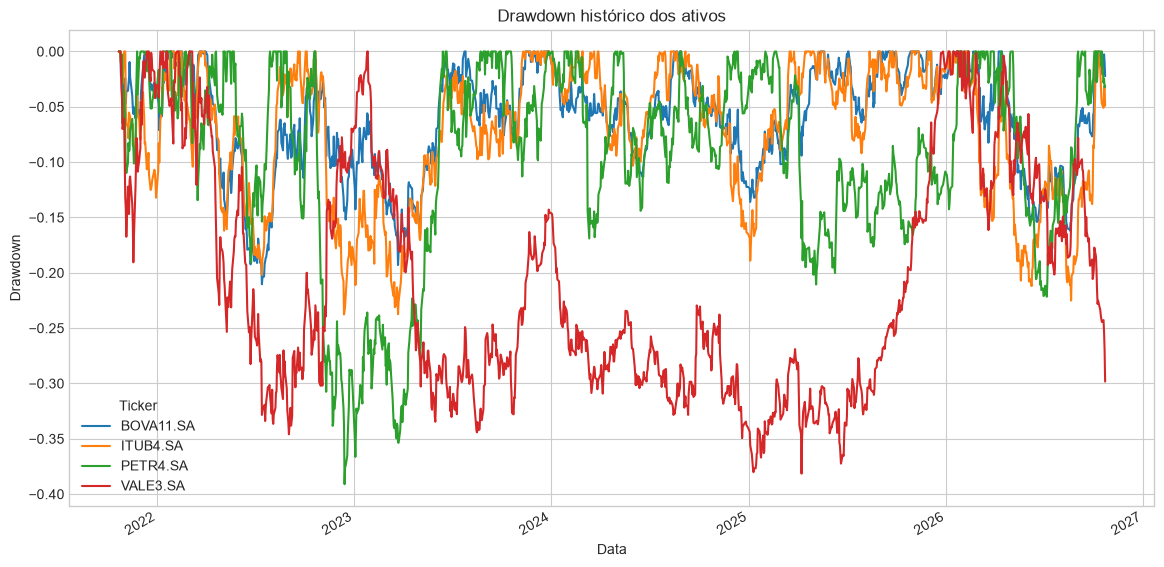

In [18]:
drawdown.plot(
    figsize=(14, 7),
    title="Drawdown histórico dos ativos"
)

plt.xlabel("Data")
plt.ylabel("Drawdown")
salvar_figura("drawdown.png")
plt.show()

In [19]:
max_drawdown = drawdown.min()

print("Maximum Drawdown:")
print((max_drawdown * 100).round(2))

Maximum Drawdown:
Ticker
BOVA11.SA   -21.03
ITUB4.SA    -23.76
PETR4.SA    -39.10
VALE3.SA    -38.15
dtype: float64


#### PETR4 apresentou o maior drawdown, com perda máxima de 39,10%;
#### VALE3 ficou próxima, com 38,15%;
#### ITUB4 apresentou drawdown intermediário, de 23,76%;
#### BOVA11 teve o menor drawdown, de 21,03%.


In [20]:
peak_dates = {}

for asset in prices.columns:
    drawdown_date = drawdown[asset].idxmin()
    
    wealth_until_drawdown = wealth_index[asset].loc[:drawdown_date]
    peak_date = wealth_until_drawdown.idxmax()
    
    peak_dates[asset] = peak_date

peak_dates

drawdown_details = pd.DataFrame({
    "Data do pico anterior": peak_dates,
    "Data do pior drawdown": drawdown.idxmin(),
    "Maximum Drawdown": drawdown.min()
})

drawdown_details

,Data do pico anterior,Data do pior drawdown,Maximum Drawdown
BOVA11.SA,2022-04-01,2022-07-14,-0.210324
ITUB4.SA,2022-10-21,2022-12-13,-0.237643
PETR4.SA,2022-10-21,2022-12-14,-0.391042
VALE3.SA,2023-01-26,2025-04-08,-0.381481


In [21]:
underwater = drawdown < 0

days_in_drawdown = underwater.sum()

print("Número de dias em drawdown:")
print(days_in_drawdown)

Número de dias em drawdown:
Ticker
BOVA11.SA    1150
ITUB4.SA     1134
PETR4.SA     1108
VALE3.SA     1214
dtype: int64


In [22]:
final_summary = pd.DataFrame({
    "Retorno acumulado": cumulative_return,
    "Retorno anualizado": annualized_return,
    "Volatilidade anualizada": annualized_volatility,
    "Sharpe Ratio": sharpe_ratio_zero_rf,
    "Maximum Drawdown": max_drawdown
})

final_summary_display = final_summary.copy()

for column in [
    "Retorno acumulado",
    "Retorno anualizado",
    "Volatilidade anualizada",
    "Maximum Drawdown"
]:
    final_summary_display[column] = (
        final_summary_display[column] * 100
    ).round(2).astype(str) + "%"

final_summary_display["Sharpe Ratio"] = (
    final_summary_display["Sharpe Ratio"].round(3)
)

final_summary_display.sort_values(
    by="Sharpe Ratio",
    ascending=False
)

,Retorno acumulado,Retorno anualizado,Volatilidade anualizada,Sharpe Ratio,Maximum Drawdown
Ticker,,,,,
PETR4.SA,619.46%,48.4%,31.47%,1.427,-39.1%
ITUB4.SA,217.66%,26.01%,23.7%,1.104,-23.76%
BOVA11.SA,96.38%,14.45%,18.29%,0.838,-21.03%
VALE3.SA,22.21%,4.09%,29.11%,0.284,-38.15%


## Resumo dos resultados

A PETR4 teve o melhor resultado financeiro, entregando o maior ganho acumulado e o melhor retorno pelo risco (Sharpe Ratio). Mas esse lucro não veio de graça: ela também foi a que mais oscilou e a que teve a maior queda histórica. 
### Resumo dos Ativos

*   **PETR4 (Mais Lucro, Mais Susto):** Foi a grande campeã de ganhos (**619,46% acumulado**), mas exige estômago. Teve a maior variação de preço e, na sua pior queda, chegou a cair **-39,10%**.
*   **BOVA11 (Mais Segura e Estável):** Como é um ETF que reúne várias ações, a diversificação funcionou. Ela foi a mais estável de todas, registrando a menor oscilação e a menor queda máxima (**-21,03%**).
*   **ITUB4 (Equilíbrio):** Segundo maior retorno acumulado (**217,66%**) e segundo maior Sharpe Ratio (**1,104**), com queda máxima de **-23,76%**, bem menor que a de PETR4 e VALE3. Foi também a ação mais correlacionada com o BOVA11.
*   **VALE3 (Pior Relação Custo-Benefício):** Teve o pior rendimento do grupo e, mesmo assim, caiu quase tanto quanto a PETR4. Ela prova que, no mercado financeiro, render menos não significa necessariamente ser mais segura.


## 6. Análise de correlação

A correlação mede a intensidade e a direção da relação linear entre os
retornos dos ativos.

O coeficiente de correlação varia entre -1 e 1:

- próximo de 1: os ativos tendem a se movimentar na mesma direção;
- próximo de 0: pouca relação linear;
- próximo de -1: os ativos tendem a se movimentar em direções opostas.

In [23]:
correlation_matrix = returns.corr()

correlation_matrix.round(3)

Ticker,BOVA11.SA,ITUB4.SA,PETR4.SA,VALE3.SA
Ticker,,,,
BOVA11.SA,1.000,0.736,0.496,0.492
ITUB4.SA,0.736,1.000,0.252,0.223
PETR4.SA,0.496,0.252,1.000,0.197
VALE3.SA,0.492,0.223,0.197,1.000


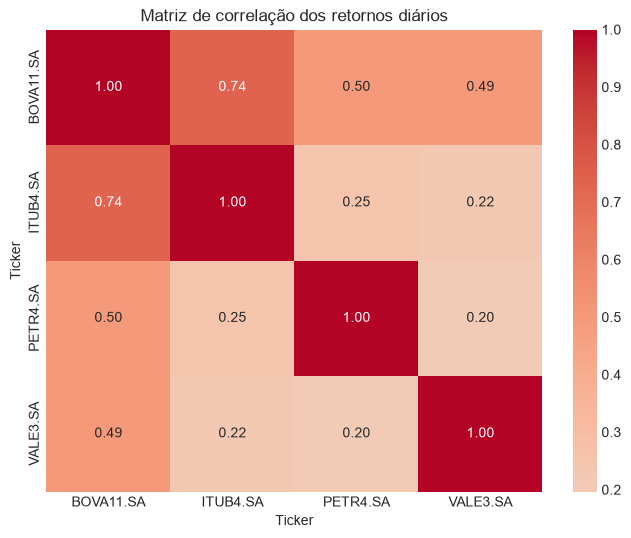

In [24]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Matriz de correlação dos retornos diários")
salvar_figura("matriz_correlacao.png")
plt.show()

In [25]:
market_correlation = (
    correlation_matrix["BOVA11.SA"]
    .drop("BOVA11.SA")
    .sort_values(ascending=False)
)

market_correlation.round(3)

Ticker
ITUB4.SA    0.736
PETR4.SA    0.496
VALE3.SA    0.492
Name: BOVA11.SA, dtype: float64

### Interpretação da correlação

Entre as ações individuais, o ativo com maior correlação com o BOVA11
foi o ativo ITUB4, com coeficiente de correlação de 0.736.

Isso indica que, durante o período analisado, os retornos diários desse
ativo apresentaram maior associação linear com os movimentos do mercado
representado pelo BOVA11.

A correlação não mede causalidade e não garante que o comportamento se
manterá no futuro.

## 7. Beta em relação ao BOVA11

O beta mede a sensibilidade de um ativo aos movimentos do mercado (aqui, o BOVA11):

\[
\beta_i = \frac{\text{Cov}(R_i, R_m)}{\text{Var}(R_m)}
\]

- beta > 1: o ativo tende a amplificar os movimentos do mercado;
- beta < 1: o ativo tende a se mover menos que o mercado;
- o BOVA11 tem beta igual a 1 por definição.

In [26]:
market_returns = returns["BOVA11.SA"]

beta = returns.apply(lambda r: r.cov(market_returns) / market_returns.var())

beta.drop("BOVA11.SA").sort_values(ascending=False).round(3)

Ticker
ITUB4.SA    0.953
PETR4.SA    0.852
VALE3.SA    0.783
dtype: float64

### Interpretação do beta

*(Escreva aqui sua análise depois de rodar o notebook.)*

- Qual ativo teve o maior beta? Ele amplifica ou suaviza os movimentos do BOVA11?
- O beta acompanha a ordem da correlação com o BOVA11? Por que o beta também depende da volatilidade do ativo?

In [27]:
final_summary_with_corr = final_summary.copy()

final_summary_with_corr["Correlação com BOVA11"] = (
    correlation_matrix["BOVA11.SA"].drop("BOVA11.SA")
)
final_summary_with_corr["Beta vs BOVA11"] = beta.drop("BOVA11.SA")

final_summary_with_corr.round(4).to_csv(DATA_DIR / "resumo_metricas.csv")

final_summary_with_corr

,Retorno acumulado,Retorno anualizado,Volatilidade anualizada,Sharpe Ratio,Maximum Drawdown,Correlação com BOVA11,Beta vs BOVA11
Ticker,,,,,,,
BOVA11.SA,0.963843,0.144536,0.182940,0.837535,-0.210324,NaN,NaN
ITUB4.SA,2.176642,0.260107,0.237016,1.104484,-0.237643,0.735841,0.953350
PETR4.SA,6.194617,0.483970,0.314714,1.426781,-0.391042,0.495519,0.852446
VALE3.SA,0.222111,0.040937,0.291149,0.284137,-0.381481,0.492171,0.783290


# Conclusão

PETR4 apresentou o maior retorno acumulado e anualizado entre os ativos
analisados, além do maior Sharpe Ratio. Entretanto, também apresentou a
maior volatilidade anualizada e o maior Maximum Drawdown, indicando que
seu desempenho veio acompanhado de oscilações e perdas temporárias mais
intensas.

ITUB4 apresentou a maior correlação com o BOVA11, com coeficiente de
0,736, indicando que seus retornos diários acompanharam mais de perto os
movimentos do mercado representado pelo ETF.

BOVA11 apresentou a menor volatilidade e o menor Maximum Drawdown da
amostra, o que pode estar relacionado ao efeito de diversificação do
fundo. Apesar disso, seu retorno e Sharpe Ratio foram inferiores aos de
PETR4 e ITUB4.

VALE3 apresentou o menor retorno acumulado, o menor retorno anualizado e
o menor Sharpe Ratio. Seu Maximum Drawdown, entretanto, foi próximo ao
de PETR4, mostrando que um retorno menor não necessariamente implica
menor risco.

Os resultados são históricos e dependem do período analisado. Portanto,
não devem ser interpretados como previsão de desempenho futuro ou
recomendação de investimento.